# Analysis of Categorical Data

Companion notebook for [notes/hypothesis_testing_and_confidence_intervals/analysis_of_categorical_data.md](../../notes/hypothesis_testing_and_confidence_intervals/analysis_of_categorical_data.md).

Chi-square tests compare observed counts with the counts expected under a null model using $\chi^2=\sum (O-E)^2/E$. We run a goodness-of-fit test (M&M colors), a test of homogeneity (Titanic), a test of independence (gender and voting), and check the null distribution by simulation.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(0)

## 1. Goodness of fit: M&M colors

$H_0$: the color proportions are the 2008 values. Expected counts are $Np_i$ and $df=k-1=5$.

Expected: [98.4 82.  65.6 57.4 53.3 53.3]
chi2 = 4.32, df = 5, critical = 11.07, p = 0.5045
Fail to reject H0


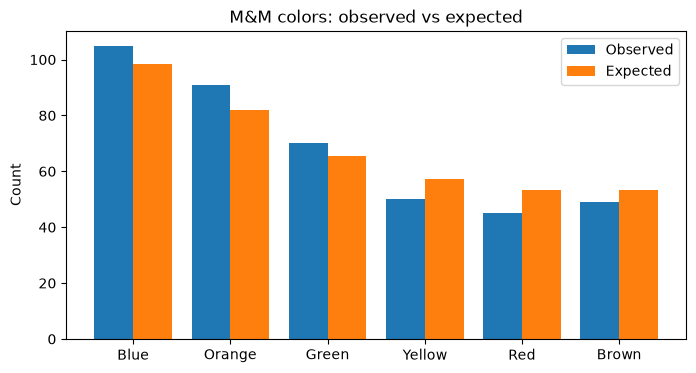

In [2]:
colors = ["Blue", "Orange", "Green", "Yellow", "Red", "Brown"]
props = np.array([0.24, 0.20, 0.16, 0.14, 0.13, 0.13])
observed = np.array([105, 91, 70, 50, 45, 49])
expected = observed.sum() * props

chi2_stat, p_val = stats.chisquare(observed, expected)
crit = stats.chi2.ppf(0.95, df=5)
print("Expected:", np.round(expected, 1))
print(f"chi2 = {chi2_stat:.2f}, df = 5, critical = {crit:.2f}, p = {p_val:.4f}")
print("Reject H0" if chi2_stat > crit else "Fail to reject H0")

idx = np.arange(6)
plt.figure(figsize=(8, 4))
plt.bar(idx - 0.2, observed, 0.4, label="Observed")
plt.bar(idx + 0.2, expected, 0.4, label="Expected")
plt.xticks(idx, colors)
plt.ylabel("Count")
plt.legend()
plt.title("M&M colors: observed vs expected")
plt.show()

The statistic is well below the critical value, so there is no evidence the color distribution changed. Note that this is *failing to reject*, not showing the distributions are equal.

## 2. Homogeneity: Titanic survival by class

Expected count in each cell is $\frac{\text{row total}\times\text{column total}}{\text{grand total}}$ and $df=(r-1)(c-1)=3$.

In [3]:
titanic = np.array([[203, 122], [118, 167], [178, 528], [212, 673]])
chi2_stat, p_val, df, exp = stats.chi2_contingency(titanic)
print("Expected counts:\n", np.round(exp, 1))
print(f"chi2 = {chi2_stat:.2f}, df = {df}, p = {p_val:.2e}")

classes = ["First", "Second", "Third", "Crew"]
print("Survival rates:", {c: round(r[0] / r.sum(), 3) for c, r in zip(classes, titanic)})

Expected counts:
 [[105.  220. ]
 [ 92.1 192.9]
 [228.1 477.9]
 [285.9 599.1]]
chi2 = 190.40, df = 3, p = 5.00e-41
Survival rates: {'First': np.float64(0.625), 'Second': np.float64(0.414), 'Third': np.float64(0.252), 'Crew': np.float64(0.24)}


First class survival (about 62%) is far above the overall rate (about 32%), which drives the very large statistic. The test shows the groups differ; it does not say why.

## 3. Independence: gender and voting, with and without Yates' correction

In [4]:
votes = np.array([[40, 60], [70, 30]])
pearson = stats.chi2_contingency(votes, correction=False)
yates = stats.chi2_contingency(votes, correction=True)
print(f"Pearson: chi2 = {pearson[0]:.2f}, p = {pearson[1]:.2e}")
print(f"Yates:   chi2 = {yates[0]:.2f}, p = {yates[1]:.2e}")
print("Expected:\n", pearson[3])

Pearson: chi2 = 18.18, p = 2.01e-05
Yates:   chi2 = 16.99, p = 3.76e-05
Expected:
 [[55. 45.]
 [55. 45.]]


The correction lowers the statistic slightly (it is conservative) but the conclusion is unchanged.

## 4. Where does the chi-square distribution come from?

If $H_0$ is true, $\chi^2$ approximately follows $\chi^2_{df}$ provided expected counts are not tiny. We verify with a simulation of fair-die rolls ($df=5$, 120 rolls).

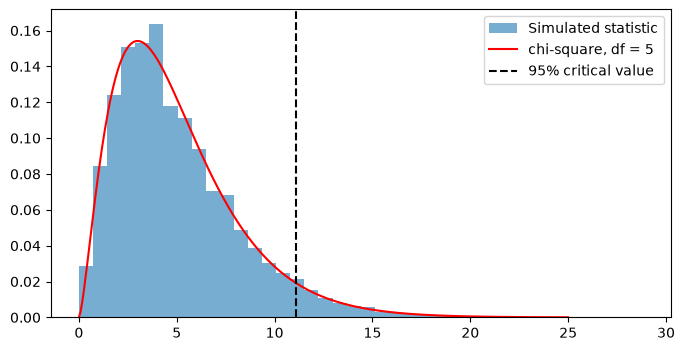

Simulated rejection rate at alpha=0.05: 0.051


In [5]:
rolls = rng.multinomial(120, [1 / 6] * 6, size=10_000)
sim_stats = ((rolls - 20) ** 2 / 20).sum(axis=1)

xs = np.linspace(0, 25, 300)
plt.figure(figsize=(8, 4))
plt.hist(sim_stats, bins=40, density=True, alpha=0.6, label="Simulated statistic")
plt.plot(xs, stats.chi2.pdf(xs, 5), "r", label="chi-square, df = 5")
plt.axvline(stats.chi2.ppf(0.95, 5), color="black", linestyle="--", label="95% critical value")
plt.legend()
plt.show()
print(f"Simulated rejection rate at alpha=0.05: {np.mean(sim_stats > stats.chi2.ppf(0.95, 5)):.3f}")

## 5. Small expected counts

When expected counts fall below about 5 the chi-square approximation can be unreliable. For a sparse 2x2 table, compare with Fisher's exact test.

In [6]:
sparse = np.array([[3, 1], [1, 5]])
chi2_stat, p_chi, _, exp = stats.chi2_contingency(sparse, correction=False)
odds, p_fisher = stats.fisher_exact(sparse)
print("Expected counts:\n", np.round(exp, 2))
print(f"Chi-square p = {p_chi:.4f}, Fisher exact p = {p_fisher:.4f}")

Expected counts:
 [[1.6 2.4]
 [2.4 3.6]]
Chi-square p = 0.0651, Fisher exact p = 0.1905


Here two expected counts are below 5, so the exact test is preferable.